In [32]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [33]:
image = cv2.imread("cat.png")
image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [34]:
height, width = image.shape


average = image.copy()
median = image.copy()
weighted = image.copy()

mask = [[1, 2, 1],
        [2, 4, 3],
        [1, 2, 1]]

for i in range(1, height - 1):
    for j in range(1, width - 1):
        total = 0
        weighted_total = 0
        pixels = []

        # Read the 3 × 3 neighborhood
        for x in range(-1, 2):
            for y in range(-1, 2):
                value = int(image[i + x, j + y])

                total += value
                pixels.append(value)
                weighted_total += value * mask[x + 1][y + 1]

        # 1. Average filter
        average[i, j] = total // 9

        # 2. Median filter: manually sort the 9 pixels
        for a in range(8):
            for b in range(a + 1, 9):
                if pixels[a] > pixels[b]:
                    pixels[a], pixels[b] = pixels[b], pixels[a]

        median[i, j] = pixels[4]

        # 3. Weighted average filter
        weighted[i, j] = weighted_total // 16


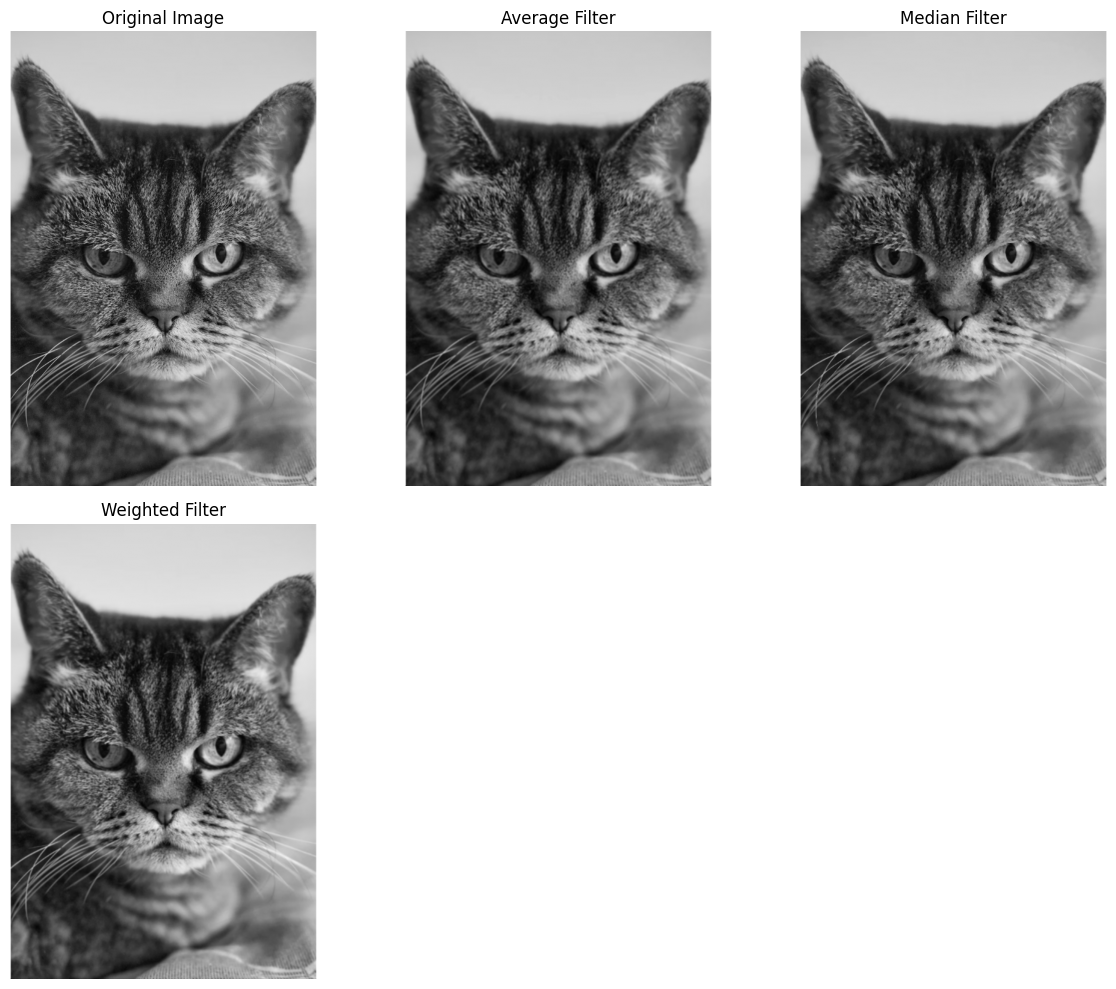

In [35]:
# Display Results
plt.figure(figsize=(12, 10))

# Original
plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

# Noisy
plt.subplot(2, 3, 2)
plt.imshow(average, cmap='gray')
plt.title("Average Filter")
plt.axis("off")

# Median
plt.subplot(2, 3, 3)
plt.imshow(median, cmap='gray')
plt.title("Median Filter")
plt.axis("off")

# Max
plt.subplot(2, 3, 4)
plt.imshow(weighted, cmap='gray')
plt.title("Weighted Filter")
plt.axis("off")



plt.tight_layout()
plt.show()
